# Predicting Hunger in WV
### Predicting the trajectory of poverty rate and population loss across WV counties til 2029 using socioeconomic indicators.



### 

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, confusion_matrix



### Step 2: Load Datasets and Data Clean up

*******

load datasets and merge them pulling out important variables.

In [5]:
import pandas as pd
# Load the socioeconomic food csv and pull out the relevant columns and filter by State=WV then drop first couple of rows
socioeconomic_data = pd.read_csv("Socioeconomic food.csv", skiprows=1, encoding="latin-1")
socioeconomic_data = socioeconomic_data[socioeconomic_data['State'] == 'WV']
socioeconomic_data = socioeconomic_data[['FIPS','State','County','PCT_18YOUNGER20','MEDHHINC21','POVRATE21','CHILDPOVRATE21','CHILDPOVRATE21','DEEPPOVRATE21']]
#load the Access food csv and pull out the relevant columns and filter by State=WV 
access_data = pd.read_csv("Access Food.csv", skiprows=1, encoding="latin-1")
access_data = access_data[access_data['State'] == 'WV']
access_data = access_data[['FIPS','State','County','PCT_LACCESS_POP15','PCT_LACCESS_POP19','PCT_LACCESS_CHILD15','PCT_LACCESS_CHILD19','PCT_LACCESS_SENIORS15','PCT_LACCESS_SENIORS19']]
#load the insequerity food csv and ilter by State=WV
insecurity_data = pd.read_csv("Insequrity food.csv", skiprows=1, encoding="latin-1")
insecurity_data = insecurity_data[insecurity_data['State'] == 'WV']
insecurity_data = insecurity_data[['FIPS','State','County','FOODINSEC_21_23','VLFOODSEC_21_23']]
# merge all these dataframes together on FIPS code and print the first couple of rows
Master_insecurity_data = insecurity_data.merge(access_data, on='FIPS')
Master_insecurity_data = Master_insecurity_data.merge(socioeconomic_data, on='FIPS')
# check for shape and head of master dataframe
print("Master Insecurity Data shape:", Master_insecurity_data.shape)
print(Master_insecurity_data.head())


Master Insecurity Data shape: (55, 21)
    FIPS State_x  County_x  FOODINSEC_21_23  VLFOODSEC_21_23 State_y  \
0  54001      WV   Barbour             13.7              4.1      WV   
1  54003      WV  Berkeley             13.7              4.1      WV   
2  54005      WV     Boone             13.7              4.1      WV   
3  54007      WV   Braxton             13.7              4.1      WV   
4  54009      WV    Brooke             13.7              4.1      WV   

   County_y  PCT_LACCESS_POP15  PCT_LACCESS_POP19  PCT_LACCESS_CHILD15  ...  \
0   Barbour          11.397135          11.415004            76.942810  ...   
1  Berkeley          38.373856          38.801971            69.421211  ...   
2     Boone           4.603291           6.627663            83.002777  ...   
3   Braxton          19.071209          18.252140            96.066551  ...   
4    Brooke          17.875412          16.895472            63.251598  ...   

   PCT_LACCESS_SENIORS15  PCT_LACCESS_SENIORS19  Stat

In [6]:
#Load the population estimates csv and pull out the relevant columns
population_estimates = pd.read_csv("Population estimates WV.csv", encoding="latin-1", header=3)
population_estimates = population_estimates[['Geographic Area', ' 2020 Estimates Base', 'POP_EST_2020', 'POP_EST_2021', 'POP_EST_2022', 'POP_EST_2023', 'POP_EST_2024', 'POP_EST_2025']]

# filter to counties only and drop any empty rows
population_estimates = population_estimates[population_estimates['Geographic Area'].str.contains('County', na=False)]
population_estimates = population_estimates.dropna()

# clean county name
population_estimates['Geographic Area'] = population_estimates['Geographic Area'].str.replace('.', '', regex=False)
population_estimates['Geographic Area'] = population_estimates['Geographic Area'].str.replace(', West Virginia', '', regex=False).str.strip()

# convert number columns
number_cols = [' 2020 Estimates Base', 'POP_EST_2020', 'POP_EST_2021', 'POP_EST_2022', 'POP_EST_2023', 'POP_EST_2024', 'POP_EST_2025']
for col in number_cols:
    population_estimates[col] = population_estimates[col].str.replace(',', '').astype(int)

print(population_estimates.shape)
print(population_estimates.head())


(55, 8)
   Geographic Area   2020 Estimates Base  POP_EST_2020  POP_EST_2021  \
1   Barbour County                 15461         15463         15446   
2  Berkeley County                122073        122693        126208   
3     Boone County                 21811         21746         21365   
4   Braxton County                 12450         12400         12303   
5    Brooke County                 22557         22481         22079   

   POP_EST_2022  POP_EST_2023  POP_EST_2024  POP_EST_2025  
1         15397         15448         15336         15414  
2        129515        132742        135990        139522  
3         20927         20609         20448         20251  
4         12163         12144         12054         11885  
5         21731         21423         21294         21142  


In [7]:
#load the population change csv and pull out the relevant columns
population_change = pd.read_csv("Componentes of population change.csv", encoding="latin-1", header=4)

# rename all columns by position since the headers span multiple rows
population_change.columns = [
    'Geographic Area',
    'total_pop_change_24_25',
    'natural_change_24_25',
    'births_24_25',
    'deaths_24_25',
    'net_migration_24_25',
    'international_migration_24_25',
    'domestic_migration_24_25',
    'total_pop_change_20_25',
    'natural_change_20_25',
    'births_20_25',
    'deaths_20_25',
    'net_migration_20_25',
    'international_migration_20_25',
    'domestic_migration_20_25'
]

# keep only counties, drop state total and empty rows
population_change = population_change[population_change['Geographic Area'].str.contains('County', na=False)]
population_change = population_change.dropna(subset=['Geographic Area'])

# clean county name
population_change['Geographic Area'] = population_change['Geographic Area'].str.replace('.', '', regex=False)
population_change['Geographic Area'] = population_change['Geographic Area'].str.replace(', West Virginia', '', regex=False).str.strip()

# keep only the relevant columns
population_change = population_change[['Geographic Area', 'total_pop_change_24_25','natural_change_24_25','births_24_25', 'deaths_24_25', 'domestic_migration_24_25', 'total_pop_change_20_25', 'domestic_migration_20_25']]

# convert to numeric
for col in population_change.columns[1:]:
    population_change[col] = pd.to_numeric(population_change[col].astype(str).str.replace(',', ''), errors='coerce')

print(population_change.shape)
print(population_change.head())

(55, 8)
   Geographic Area  total_pop_change_24_25  natural_change_24_25  \
1   Barbour County                      78                   -76   
2  Berkeley County                    3532                   389   
3     Boone County                    -197                  -184   
4   Braxton County                    -169                   -95   
5    Brooke County                    -152                  -152   

   births_24_25  deaths_24_25  domestic_migration_24_25  \
1           157           233                       154   
2          1632          1243                      3186   
3           170           354                       -16   
4            91           186                       -73   
5           172           324                       -12   

   total_pop_change_20_25  domestic_migration_20_25  
1                     -47                       372  
2                   17449                     15917  
3                   -1560                      -625  
4           

In [8]:
# fix county names in both population dataframes first
population_estimates['Geographic Area'] = population_estimates['Geographic Area'].str.replace(' County', '', regex=False).str.strip()
population_change['Geographic Area'] = population_change['Geographic Area'].str.replace(' County', '', regex=False).str.strip()

# merge population estimates and population change
population_data = population_estimates.merge(population_change, on='Geographic Area')

# rename Geographic Area to County before merging with master
population_data = population_data.rename(columns={'Geographic Area': 'County'})

# merge into master insecurity data
Master_data = Master_insecurity_data.merge(population_data, on='County')
#clean up duplicate columns
Master_data = Master_data.drop(columns=['State_x', 'State_y','County_x','County_y'], errors='ignore')
Master_data = Master_data.loc[:,~Master_data.columns.duplicated()]
Master_data = Master_data.rename(columns={' 2020 Estimates Base': 'Estimates Base 2020'})
print("Master Data shape:", Master_data.shape)
print("\nColumns:", Master_data.columns.tolist())
print("\n", Master_data.head())

Master Data shape: (55, 30)

Columns: ['FIPS', 'FOODINSEC_21_23', 'VLFOODSEC_21_23', 'PCT_LACCESS_POP15', 'PCT_LACCESS_POP19', 'PCT_LACCESS_CHILD15', 'PCT_LACCESS_CHILD19', 'PCT_LACCESS_SENIORS15', 'PCT_LACCESS_SENIORS19', 'State', 'County', 'PCT_18YOUNGER20', 'MEDHHINC21', 'POVRATE21', 'CHILDPOVRATE21', 'DEEPPOVRATE21', 'Estimates Base 2020', 'POP_EST_2020', 'POP_EST_2021', 'POP_EST_2022', 'POP_EST_2023', 'POP_EST_2024', 'POP_EST_2025', 'total_pop_change_24_25', 'natural_change_24_25', 'births_24_25', 'deaths_24_25', 'domestic_migration_24_25', 'total_pop_change_20_25', 'domestic_migration_20_25']

     FIPS  FOODINSEC_21_23  VLFOODSEC_21_23  PCT_LACCESS_POP15  \
0  54001             13.7              4.1          11.397135   
1  54003             13.7              4.1          38.373856   
2  54005             13.7              4.1           4.603291   
3  54007             13.7              4.1          19.071209   
4  54009             13.7              4.1          17.875412   

 

In [9]:

# check for missing values
print(Master_data.isnull().sum())

# basic statistics
print(Master_data.describe())


FIPS                        0
FOODINSEC_21_23             0
VLFOODSEC_21_23             0
PCT_LACCESS_POP15           0
PCT_LACCESS_POP19           0
PCT_LACCESS_CHILD15         0
PCT_LACCESS_CHILD19         0
PCT_LACCESS_SENIORS15       0
PCT_LACCESS_SENIORS19       0
State                       0
County                      0
PCT_18YOUNGER20             0
MEDHHINC21                  0
POVRATE21                   0
CHILDPOVRATE21              0
DEEPPOVRATE21               0
Estimates Base 2020         0
POP_EST_2020                0
POP_EST_2021                0
POP_EST_2022                0
POP_EST_2023                0
POP_EST_2024                0
POP_EST_2025                0
total_pop_change_24_25      0
natural_change_24_25        0
births_24_25                0
deaths_24_25                0
domestic_migration_24_25    0
total_pop_change_20_25      0
domestic_migration_20_25    0
dtype: int64
              FIPS  FOODINSEC_21_23  VLFOODSEC_21_23  PCT_LACCESS_POP15  \
count     55

Test statistical modeles and figure out final Model.

In [10]:
import statsmodels.api as sm

# select features
features_ols = Master_data[['DEEPPOVRATE21', 'CHILDPOVRATE21', 'MEDHHINC21','PCT_18YOUNGER20', 'PCT_LACCESS_POP19','domestic_migration_24_25', 'natural_change_24_25','total_pop_change_20_25', 'births_24_25',
'deaths_24_25','domestic_migration_20_25','PCT_LACCESS_SENIORS19', 'PCT_LACCESS_CHILD19']]

target = Master_data['POVRATE21']

# add constant for intercept
X = sm.add_constant(features_ols)

# build OLS model
ols_model = sm.OLS(target, X).fit()

# print full summary
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:              POVRATE21   R-squared:                       0.875
Model:                            OLS   Adj. R-squared:                  0.839
Method:                 Least Squares   F-statistic:                     24.43
Date:                Tue, 28 Apr 2026   Prob (F-statistic):           3.97e-15
Time:                        01:07:44   Log-Likelihood:                -104.73
No. Observations:                  55   AIC:                             235.5
Df Residuals:                      42   BIC:                             261.6
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

In [11]:
features_ols = Master_data[['CHILDPOVRATE21', 'DEEPPOVRATE21']]

X = sm.add_constant(features_ols)
ols_model = sm.OLS(target, X).fit()
print(ols_model.summary())
features_ols2 = Master_data[['CHILDPOVRATE21', 'DEEPPOVRATE21']]

X2 = sm.add_constant(features_ols2)
ols_model2 = sm.OLS(target, X2).fit()
print(ols_model2.summary())

                            OLS Regression Results                            
Dep. Variable:              POVRATE21   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.828
Method:                 Least Squares   F-statistic:                     130.8
Date:                Tue, 28 Apr 2026   Prob (F-statistic):           5.15e-21
Time:                        01:07:45   Log-Likelihood:                -112.44
No. Observations:                  55   AIC:                             230.9
Df Residuals:                      52   BIC:                             236.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.1943      1.148      0.

In [12]:
# final model - by removing multicollinearity
features_final = Master_data[['CHILDPOVRATE21', 'DEEPPOVRATE21']]

X_final = sm.add_constant(features_final)
ols_final = sm.OLS(target, X_final).fit()
print(ols_final.summary())
# check the current values to understand the range
print(Master_data[['County', 'CHILDPOVRATE21', 'DEEPPOVRATE21', 'POVRATE21']].sort_values('POVRATE21', ascending=False).head(10))

                            OLS Regression Results                            
Dep. Variable:              POVRATE21   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.828
Method:                 Least Squares   F-statistic:                     130.8
Date:                Tue, 28 Apr 2026   Prob (F-statistic):           5.15e-21
Time:                        01:07:48   Log-Likelihood:                -112.44
No. Observations:                  55   AIC:                             230.9
Df Residuals:                      52   BIC:                             236.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.1943      1.148      0.

Predict the poverty average in WV

In [ ]:
# predict 2021 poverty using model equation
Master_data['POVRATE_predicted'] = 0.1943 + (0.6296 * Master_data['CHILDPOVRATE21']) + (0.3961 * Master_data['DEEPPOVRATE21'])

# find counties where predicted poverty is above WV average
wv_avg = Master_data['POVRATE21'].mean()
print("WV Average Poverty Rate:", round(wv_avg, 2))

rising_counties = Master_data[Master_data['POVRATE21'] > wv_avg][['County', 'POVRATE21', 'CHILDPOVRATE21', 'DEEPPOVRATE21', 'domestic_migration_24_25', 'total_pop_change_20_25']].sort_values('POVRATE21', ascending=False)

print("\nCounties ABOVE average poverty rate:")
print(rising_counties)

WV Average Poverty Rate: 18.06

Counties ABOVE average poverty rate:
        County  POVRATE21  CHILDPOVRATE21  DEEPPOVRATE21  \
23    McDowell       31.7            40.2      14.265812   
29       Mingo       31.1            35.8      14.043594   
10      Gilmer       25.3            23.8       5.930233   
50     Webster       25.2            36.3       4.709971   
54     Wyoming       25.0            28.4       9.125850   
44     Summers       24.8            29.9       7.214499   
2        Boone       24.7            28.2       5.770558   
6      Calhoun       23.8            32.0      14.613812   
22       Logan       23.5            30.2      13.090762   
7         Clay       22.3            31.0      11.993537   
40     Raleigh       22.0            25.8      11.671014   
3      Braxton       21.3            29.0       7.739637   
21     Lincoln       20.3            26.7       9.948156   
9      Fayette       19.9            23.6       7.471395   
33    Nicholas       19.8      

Find out the counties that have a declining trend

In [ ]:
years = [2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029]

predictions = []

for county in Master_data['County']:
    row = Master_data[Master_data['County'] == county].iloc[0]
    child_pov = row['CHILDPOVRATE21']
    deep_pov = row['DEEPPOVRATE21']
    
    county_preds = {'County': county}
    for i, year in enumerate(years):
        child_pov_proj = child_pov - (0.5 * i)
        deep_pov_proj = deep_pov - (0.3 * i)
        
        # predict poverty rate using Model equation
        pov_pred = 0.1943 + (0.6296 * child_pov_proj) + (0.3961 * deep_pov_proj)
        county_preds[str(year)] = round(pov_pred, 2)
    
    predictions.append(county_preds)

poverty_predictions = pd.DataFrame(predictions)
print(poverty_predictions.columns.tolist())
print(poverty_predictions.head())

['County', '2021', '2022', '2023', '2024', '2025', '2026', '2027', '2028', '2029']
     County   2021   2022   2023   2024   2025   2026   2027   2028   2029
0   Barbour  21.36  20.93  20.49  20.06  19.63  19.19  18.76  18.33  17.89
1  Berkeley  10.05   9.61   9.18   8.75   8.31   7.88   7.45   7.01   6.58
2     Boone  20.23  19.80  19.37  18.93  18.50  18.07  17.63  17.20  16.77
3   Braxton  21.52  21.08  20.65  20.22  19.78  19.35  18.92  18.48  18.05
4    Brooke  13.98  13.55  13.11  12.68  12.25  11.81  11.38  10.94  10.51


Graph the top counties with decling poverty rate predictions.

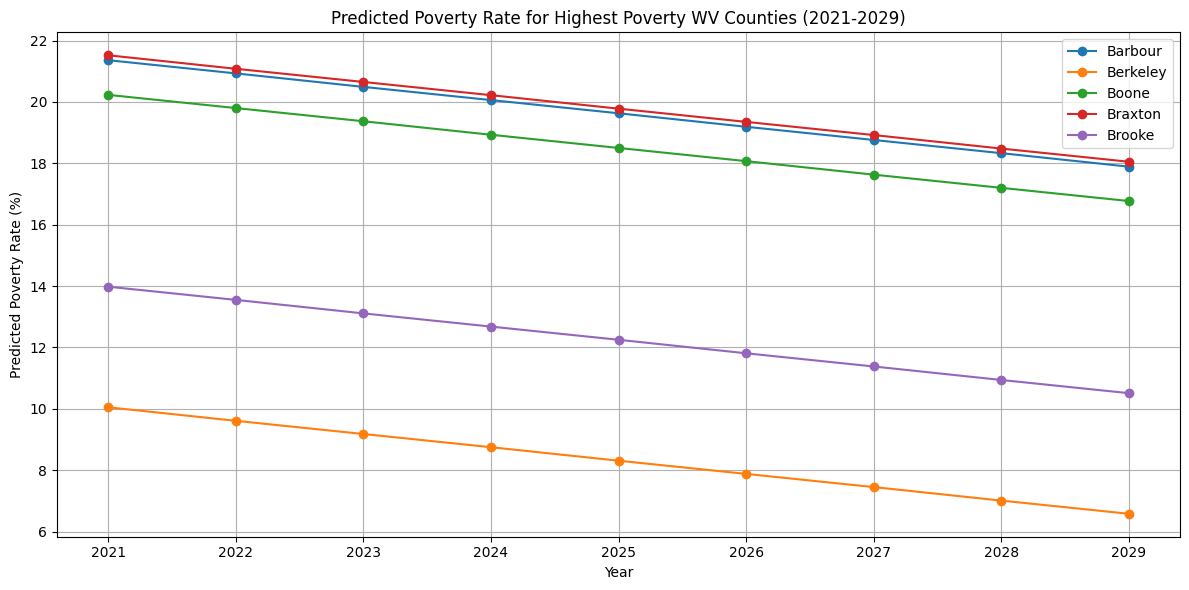

In [40]:
top_counties = ['Barbour', 'Berkeley', 'Boone', 'Braxton', 'Brooke']
years_str = ['2021', '2022', '2023', '2024', '2025', '2026', '2027', '2028', '2029']
years_int = [2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029]

plt.figure(figsize=(12, 6))
for county in top_counties:
    row = poverty_predictions[poverty_predictions['County'] == county]
    values = row[years_str].values.flatten()
    plt.plot(years_int, values, marker='o', label=county)

plt.xlabel('Year')
plt.ylabel('Predicted Poverty Rate (%)')
plt.title('Predicted Poverty Rate for Highest Poverty WV Counties (2021-2029)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Figure out  top counties with declining population predictions

In [16]:
# project population for each county to 2029
pop_years = [2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029]
pop_predictions = []

for idx, row in Master_data.iterrows():
    county_preds = {'County': row['County']}
    
    # calculate average annual change from 2020-2025
    annual_change = (row['POP_EST_2025'] - row['POP_EST_2020']) / 5
    
    # fill in known years
    for year in [2020, 2021, 2022, 2023, 2024, 2025]:
        county_preds[str(year)] = row[f'POP_EST_{year}']
    
    # project forward
    for i, year in enumerate([2026, 2027, 2028, 2029], 1):
        county_preds[str(year)] = int(row['POP_EST_2025'] + (annual_change * i))
    
    pop_predictions.append(county_preds)

pop_predictions_df = pd.DataFrame(pop_predictions)

# show top 5 counties losing population
losing = Master_data.nsmallest(5, 'total_pop_change_20_25')['County'].tolist()
print(pop_predictions_df[pop_predictions_df['County'].isin(losing)][['County', '2020', '2021', '2022', '2023', '2024', '2025', '2026', '2027', '2028', '2029']])

      County    2020    2021    2022    2023    2024    2025    2026    2027  \
5     Cabell   94245   93439   92492   92017   91455   91183   90570   89958   
9    Fayette   40442   40064   39408   39060   38554   38165   37709   37254   
19   Kanawha  180215  178124  175864  174434  173423  172381  170814  169247   
23  McDowell   18942   18421   17795   17446   17186   16878   16465   16052   
40   Raleigh   74404   73817   72858   72504   72185   71775   71249   70723   

      2028    2029  
5    89345   88733  
9    36798   36343  
19  167680  166113  
23   15639   15226  
40   70197   69671  


In [17]:
pop_years = [2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029]
pop_predictions = []

for idx, row in Master_data.iterrows():
    county_preds = {'County': row['County']}
    
    annual_change = (row['POP_EST_2025'] - row['POP_EST_2020']) / 5
    
    for year in [2020, 2021, 2022, 2023, 2024, 2025]:
        county_preds[str(year)] = row[f'POP_EST_{year}']
    
    for i, year in enumerate([2026, 2027, 2028, 2029], 1):
        county_preds[str(year)] = int(row['POP_EST_2025'] + (annual_change * i))
    
    pop_predictions.append(county_preds)

pop_predictions_df = pd.DataFrame(pop_predictions)

pop_predictions_df['pop_change_20_29'] = pop_predictions_df['2029'].astype(int) - pop_predictions_df['2020'].astype(int)
pop_predictions_df['pct_change'] = round((pop_predictions_df['pop_change_20_29'] / pop_predictions_df['2020'].astype(int)) * 100, 1)

print(pop_predictions_df[['County', '2020', '2029', 'pop_change_20_29', 'pct_change']].sort_values('pct_change').head(10))

      County   2020   2029  pop_change_20_29  pct_change
23  McDowell  18942  15226             -3716       -19.6
29     Mingo  23489  19827             -3662       -15.6
50   Webster   8354   7284             -1070       -12.8
54   Wyoming  21322  18584             -2738       -12.8
2      Boone  21746  19055             -2691       -12.4
22     Logan  32514  28663             -3851       -11.8
4     Brooke  22481  20070             -2411       -10.7
52      Wirt   5187   4632              -555       -10.7
7       Clay   8009   7161              -848       -10.6
21   Lincoln  20369  18223             -2146       -10.5


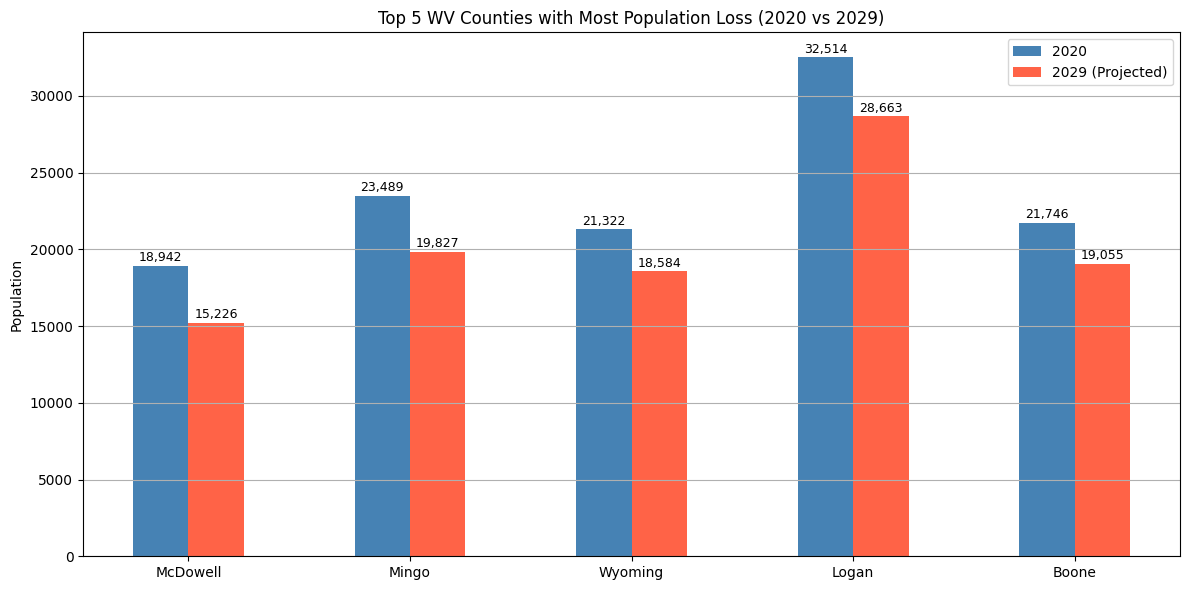

In [20]:
# get 2020 and 2029 population for top 5 losing counties
top5_loss = ['McDowell', 'Mingo', 'Wyoming', 'Logan', 'Boone']

pop_2020 = []
pop_2029 = []

for county in top5_loss:
    row = pop_predictions_df[pop_predictions_df['County'] == county].iloc[0]
    pop_2020.append(int(row['2020']))
    pop_2029.append(int(row['2029']))

x = range(len(top5_loss))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar([i - width/2 for i in x], pop_2020, width, label='2020', color='steelblue')
bars2 = ax.bar([i + width/2 for i in x], pop_2029, width, label='2029 (Projected)', color='tomato')

# add value labels on top of bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=9)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{int(bar.get_height()):,}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(top5_loss)
ax.set_ylabel('Population')
ax.set_title('Top 5 WV Counties with Most Population Loss (2020 vs 2029)')
ax.legend()
ax.grid(True, axis='y')
plt.tight_layout()
plt.show()